# BED-2501 Statistikk – løsning av øvingsoppgavene i Python

Notebooken regner ut svarene på alle de 66 øvingsoppgavene. Nummereringen følger oppgavedokumentet
(oppgave 1.1–22.3). Datasettene er simulert med faste seeds, så du får de samme tallene som i utskriftene
i oppgavesettet.

På eksamen har du ikke Python, men det er nyttig å se hvordan tallene i utskriftene blir til.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

pd.set_option("display.precision", 3)

## Datasettene

Funksjonene under lager de simulerte datasettene som er brukt i oppgavene 4, 5, 20, 21 og 22.

In [2]:
def lag_data_4a():
    """Månedlig husleie (kr) for studenthybler (samskipnaden) og private hybler."""
    rng = np.random.default_rng(4101)
    samskip = np.round(rng.normal(5200, 550, 70) / 50) * 50
    privat = np.round((4200 + rng.lognormal(7.3, 0.75, 85)) / 50) * 50
    return pd.DataFrame({
        "husleie": np.concatenate([samskip, privat]),
        "type": ["Samskipnaden"] * 70 + ["Privat"] * 85,
    })


def lag_data_4b():
    """Reisetid til campus (minutter) for studenter som sykler og studenter som tar buss."""
    rng = np.random.default_rng(4202)
    sykkel = np.round(np.clip(rng.normal(18, 5, 60), 4, None))
    buss = np.round(5 + rng.gamma(2.0, 9.0, 75))
    return pd.DataFrame({
        "reisetid": np.concatenate([sykkel, buss]),
        "transport": ["Sykkel"] * 60 + ["Buss"] * 75,
    })


def lag_data_4c():
    """Eksamenspoeng (0-100) for to kull."""
    rng = np.random.default_rng(4303)
    kull25 = np.round(np.clip(100 - rng.gamma(2.2, 11.0, 90), 0, 100))
    kull26 = np.round(np.clip(rng.normal(62, 12, 95), 0, 100))
    return pd.DataFrame({
        "poeng": np.concatenate([kull25, kull26]),
        "kull": ["Kull 2025"] * 90 + ["Kull 2026"] * 95,
    })


def _korrelert(navn, R, n, seed, mu, sd):
    rng = np.random.default_rng(seed)
    X = rng.multivariate_normal(np.zeros(len(navn)), np.array(R), n)
    return pd.DataFrame(X * np.array(sd) + np.array(mu), columns=navn)


def lag_data_5a():
    navn = ["Studietimer", "Karakter", "Skjermtid", "Sovn", "Alder"]
    R = [[1.00, 0.55, -0.30, 0.10, 0.05],
         [0.55, 1.00, -0.35, 0.20, 0.00],
         [-0.30, -0.35, 1.00, -0.25, -0.15],
         [0.10, 0.20, -0.25, 1.00, 0.05],
         [0.05, 0.00, -0.15, 0.05, 1.00]]
    return _korrelert(navn, R, 150, 5101, [20, 3.5, 4, 7, 24], [6, 0.8, 1.5, 1, 4])


def lag_data_5b():
    navn = ["Pris", "Areal", "Rom", "Avstand", "Byggaar"]
    R = [[1.00, 0.80, 0.60, -0.45, 0.25],
         [0.80, 1.00, 0.75, -0.10, 0.10],
         [0.60, 0.75, 1.00, -0.05, 0.05],
         [-0.45, -0.10, -0.05, 1.00, -0.20],
         [0.25, 0.10, 0.05, -0.20, 1.00]]
    return _korrelert(navn, R, 150, 5202, [4.2, 75, 3, 6, 1985], [1.2, 20, 1, 3, 20])


def lag_data_5c():
    navn = ["Trening", "Hvilepuls", "Vekt", "Hoyde", "Sovn"]
    R = [[1.00, -0.50, -0.15, 0.05, 0.15],
         [-0.50, 1.00, 0.20, 0.00, -0.10],
         [-0.15, 0.20, 1.00, 0.60, 0.00],
         [0.05, 0.00, 0.60, 1.00, 0.05],
         [0.15, -0.10, 0.00, 0.05, 1.00]]
    return _korrelert(navn, R, 150, 5303, [5, 62, 74, 175, 7.2], [3, 8, 12, 9, 0.9])


def _grupper(navn, n, mu, sd, seed, desimaler=1):
    rng = np.random.default_rng(seed)
    verdier, grupper = [], []
    for g, ni, m, s in zip(navn, n, mu, sd):
        verdier.append(np.round(rng.normal(m, s, ni), desimaler))
        grupper += [g] * ni
    return np.concatenate(verdier), grupper


def lag_data_20a():
    """Ukentlig studietid (timer) etter fakultet."""
    y, g = _grupper(["Okonomi", "Ingenior", "Helse", "Samfunn"], [42, 38, 45, 40],
                    [24, 28, 30, 25], [7, 7, 7, 7], 2001)
    return pd.DataFrame({"studietid": y, "fakultet": g})


def lag_data_20b():
    """Ventetid i kø (minutter) i tre kantiner."""
    y, g = _grupper(["Kantine A", "Kantine B", "Kantine C"], [35, 40, 30],
                    [6.2, 6.3, 6.1], [2, 2, 2], 2002)
    return pd.DataFrame({"ventetid": y, "kantine": g})


def lag_data_20c():
    """Pris for en kaffe latte (kr) i fem bydeler."""
    y, g = _grupper(["Sentrum", "Nord", "Sor", "Ost", "Vest"], [18, 14, 16, 15, 20],
                    [52, 44, 46, 43, 48], [9, 3, 4, 3, 8], 2003, desimaler=0)
    return pd.DataFrame({"pris": y, "bydel": g})


def lag_data_21a():
    """Månedlig hybelleie (kr) og areal (m2)."""
    rng = np.random.default_rng(2101)
    areal = np.round(rng.uniform(12, 40, 90))
    leie = np.round(2500 + 150 * areal + rng.normal(0, 700, 90), -1)
    return pd.DataFrame({"leie": leie, "areal": areal})


def lag_data_21b():
    """Eksamenspoeng og antall studietimer per uke."""
    rng = np.random.default_rng(2102)
    timer = np.round(rng.uniform(5, 35, 120))
    poeng = np.round(np.clip(30 + 1.2 * timer + rng.normal(0, 10, 120), 0, 100))
    return pd.DataFrame({"poeng": poeng, "studietimer": timer})


def lag_data_21c():
    """Daglig strømforbruk (kWh) i en bolig og utetemperatur (grader C)."""
    rng = np.random.default_rng(2103)
    temp = np.round(rng.uniform(-15, 15, 100), 1)
    kwh = np.round(60 - 1.8 * temp + rng.normal(0, 8, 100), 1)
    return pd.DataFrame({"kwh": kwh, "temperatur": temp})


def lag_data_22a():
    """Hybelleie (kr) forklart med areal (m2), avstand til campus (km) og byggets alder (år)."""
    rng = np.random.default_rng(2201)
    n = 150
    areal = np.round(rng.uniform(12, 40, n))
    avstand = np.round(rng.uniform(0.5, 10, n), 1)
    alder = np.round(rng.uniform(0, 60, n))
    leie = np.round(2800 + 155 * areal - 130 * avstand + 0 * alder + rng.normal(0, 650, n), -1)
    return pd.DataFrame({"leie": leie, "areal": areal, "avstand": avstand, "alder": alder})


def lag_data_22b():
    """Eksamenspoeng forklart med studietimer, oppmøte (%) og kaffekopper per dag."""
    rng = np.random.default_rng(2202)
    n = 160
    timer = np.round(rng.uniform(5, 35, n))
    oppmote = np.round(np.clip(rng.normal(70, 18, n), 0, 100))
    kaffe = rng.integers(0, 6, n)
    poeng = np.round(np.clip(12 + 1.0 * timer + 0.30 * oppmote + 0 * kaffe + rng.normal(0, 9, n), 0, 100))
    return pd.DataFrame({"poeng": poeng, "studietimer": timer, "oppmote": oppmote, "kaffe": kaffe})


def lag_data_22c():
    """Boligpris (mill. kr) forklart med areal (m2), antall soverom og avstand til sentrum (km)."""
    rng = np.random.default_rng(2203)
    n = 200
    areal = np.round(rng.uniform(30, 140, n))
    soverom = np.clip(np.round(areal / 30 + rng.normal(0, 0.6, n)), 1, 5)
    avstand = np.round(rng.uniform(0.5, 15, n), 1)
    pris = np.round(1.0 + 0.040 * areal + 0.05 * soverom - 0.11 * avstand + rng.normal(0, 0.55, n), 2)
    return pd.DataFrame({"pris": pris, "areal": areal, "soverom": soverom, "avstand": avstand})

## 1 Sentralmål fra frekvenstabell

`np.repeat` gjør frekvenstabellen om til en liste med enkeltobservasjoner. Da kan vi bruke vanlige funksjoner.

In [3]:
def sentralmaal(x, f, verdi):
    x, f = np.array(x), np.array(f)
    data = pd.Series(np.repeat(x, f))
    print(f"n = {len(data)}")
    print(f"Gjennomsnitt = {data.mean():.3f}")
    print(f"Median = {data.median()}")
    print(f"Typetall = {data.mode().tolist()}")
    print(f"Variasjonsbredde = {data.max() - data.min()}")
    print(f"Kumulativ relativ frekvens for x <= {verdi}: {(data <= verdi).mean():.3f}")
    return data

print("Oppgave 1.1"); d11 = sentralmaal([0, 1, 2, 3, 4], [4, 9, 7, 3, 2], 2)

Oppgave 1.1
n = 25
Gjennomsnitt = 1.600
Median = 1.0
Typetall = [1]
Variasjonsbredde = 4
Kumulativ relativ frekvens for x <= 2: 0.800


In [4]:
print("Oppgave 1.2"); d12 = sentralmaal([0, 1, 2, 3, 4, 5, 6], [2, 4, 5, 8, 6, 3, 2], 2)
print("Andel med minst fem økter:", round((d12 >= 5).mean(), 3))

Oppgave 1.2
n = 30
Gjennomsnitt = 2.967
Median = 3.0
Typetall = [3]
Variasjonsbredde = 6
Kumulativ relativ frekvens for x <= 2: 0.367
Andel med minst fem økter: 0.167


In [5]:
print("Oppgave 1.3"); d13 = sentralmaal([1, 2, 3, 4, 5], [3, 6, 6, 10, 5], 3)
print("Skewness:", round(d13.skew(), 3), "(negativ = venstreskjev)")

Oppgave 1.3
n = 30
Gjennomsnitt = 3.267
Median = 3.5
Typetall = [4]
Variasjonsbredde = 4
Kumulativ relativ frekvens for x <= 3: 0.500
Skewness: -0.321 (negativ = venstreskjev)


## 2 Spredningsmål

`ddof=1` gir den empiriske variansen (deler på n − 1).

In [6]:
for navn, x in {"2.1": [2, 5, 8, 9], "2.2": [12, 15, 11, 18, 14], "2.3": [6, 7, 7, 8]}.items():
    x = np.array(x)
    print(f"Oppgave {navn}: snitt = {x.mean():.2f}, varians = {x.var(ddof=1):.3f}, "
          f"std.avvik = {x.std(ddof=1):.3f}, variasjonsbredde = {x.max() - x.min()}")

x = np.array([6, 7, 7, 8])
print("2.3 b) +1:", (x + 1).var(ddof=1).round(3), " c) ·2:", (2 * x).var(ddof=1).round(3), (2 * x).std(ddof=1).round(3))

Oppgave 2.1: snitt = 6.00, varians = 10.000, std.avvik = 3.162, variasjonsbredde = 7
Oppgave 2.2: snitt = 14.00, varians = 7.500, std.avvik = 2.739, variasjonsbredde = 7
Oppgave 2.3: snitt = 7.00, varians = 0.667, std.avvik = 0.816, variasjonsbredde = 2
2.3 b) +1: 0.667  c) ·2: 2.667 1.633


## 3 Boksplott

Boksplottene er tegnet fra fem-tallsoppsummeringen (min, Q1, median, Q3, maks).

3.1: median = 20, Q1 = 15, Q3 = 35, IQR = 20, variasjonsbredde = 55, (Q3-med) - (med-Q1) = 10  (>0 tyder på høyreskjevhet)
3.2: median = 70, Q1 = 55, Q3 = 78, IQR = 23, variasjonsbredde = 75, (Q3-med) - (med-Q1) = -7  (>0 tyder på høyreskjevhet)
3.3: median = 7, Q1 = 6, Q3 = 8, IQR = 2, variasjonsbredde = 6, (Q3-med) - (med-Q1) = 0  (>0 tyder på høyreskjevhet)


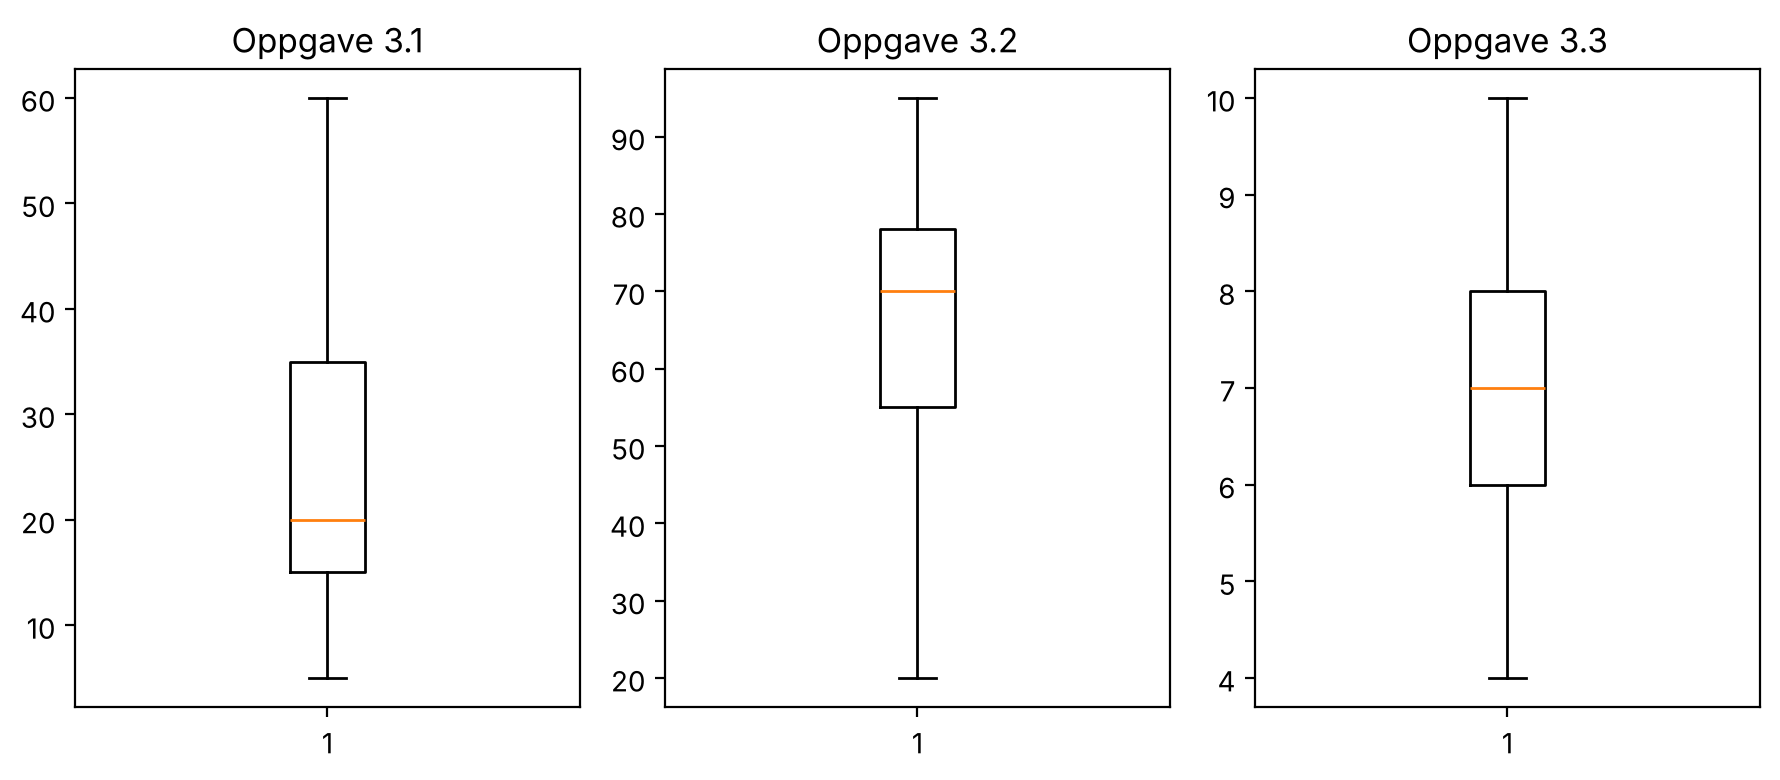

In [7]:
boks = {"3.1": (5, 15, 20, 35, 60), "3.2": (20, 55, 70, 78, 95), "3.3": (4, 6, 7, 8, 10)}
fig, axes = plt.subplots(1, 3, figsize=(9, 4))
for ax, (navn, (mn, q1, med, q3, mx)) in zip(axes, boks.items()):
    ax.bxp([{"whislo": mn, "q1": q1, "med": med, "q3": q3, "whishi": mx, "fliers": []}], showfliers=False)
    ax.set_title(f"Oppgave {navn}")
    print(f"{navn}: median = {med}, Q1 = {q1}, Q3 = {q3}, IQR = {q3 - q1}, variasjonsbredde = {mx - mn}, "
          f"(Q3-med) - (med-Q1) = {(q3 - med) - (med - q1)}  (>0 tyder på høyreskjevhet)")
plt.tight_layout(); plt.show()

## 4 Deskriptiv statistikk og histogram

`pandas` sin `skew()` og `kurt()` gir skewness og *excess* kurtosis (0 for normalfordeling).

,N,Mean,Median,Std,Min,Q1,Q3,Max,Skew,Kurt
type,,,,,,,,,,
Privat,85,6180.000,5750.0,1590.058,4500.0,5200.0,6550.0,15100.0,2.704,11.411
Samskipnaden,70,5171.429,5150.0,543.110,4050.0,4800.0,5400.0,6500.0,0.396,0.015


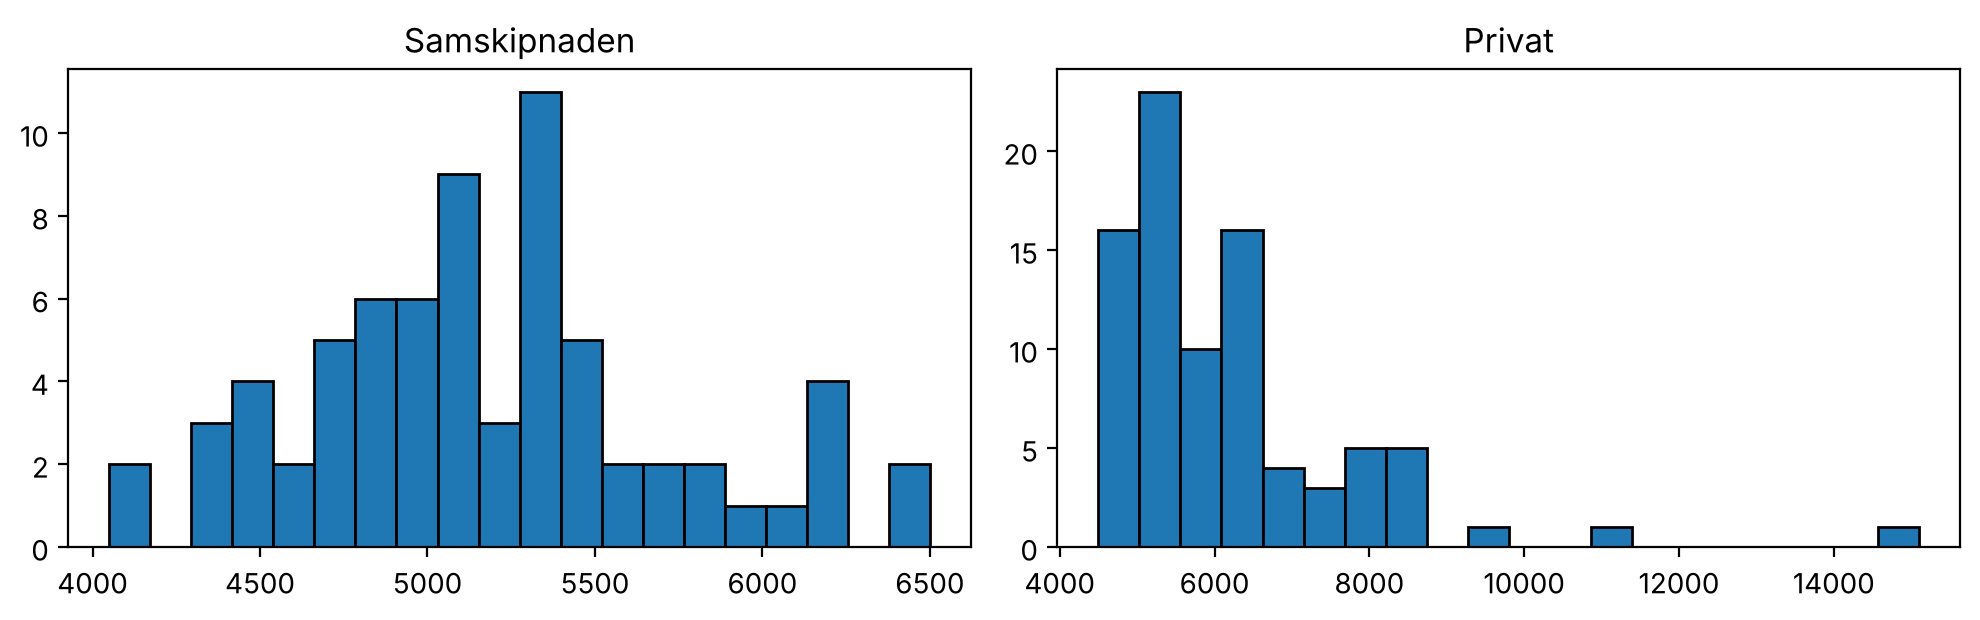

In [8]:
def beskriv(d, y, g):
    return d.groupby(g)[y].agg(
        N="count", Mean="mean", Median="median", Std="std", Min="min",
        Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75), Max="max",
        Skew="skew", Kurt=lambda s: s.kurt())

def histogrammer(d, y, g):
    grupper = d[g].unique()
    fig, axes = plt.subplots(1, len(grupper), figsize=(10, 3.2))
    for ax, gr in zip(axes, grupper):
        ax.hist(d.loc[d[g] == gr, y], bins=20, edgecolor="black")
        ax.set_title(gr)
    plt.tight_layout(); plt.show()

d4a = lag_data_4a()
display(beskriv(d4a, "husleie", "type"))
histogrammer(d4a, "husleie", "type")

,N,Mean,Median,Std,Min,Q1,Q3,Max,Skew,Kurt
transport,,,,,,,,,,
Buss,75,25.453,22.0,15.169,5.0,14.0,33.0,92.0,1.628,4.392
Sykkel,60,18.167,18.0,4.195,8.0,15.0,21.0,29.0,0.224,0.267


Kvartilbredde:
transport
Buss      19.0
Sykkel     6.0
dtype: float64


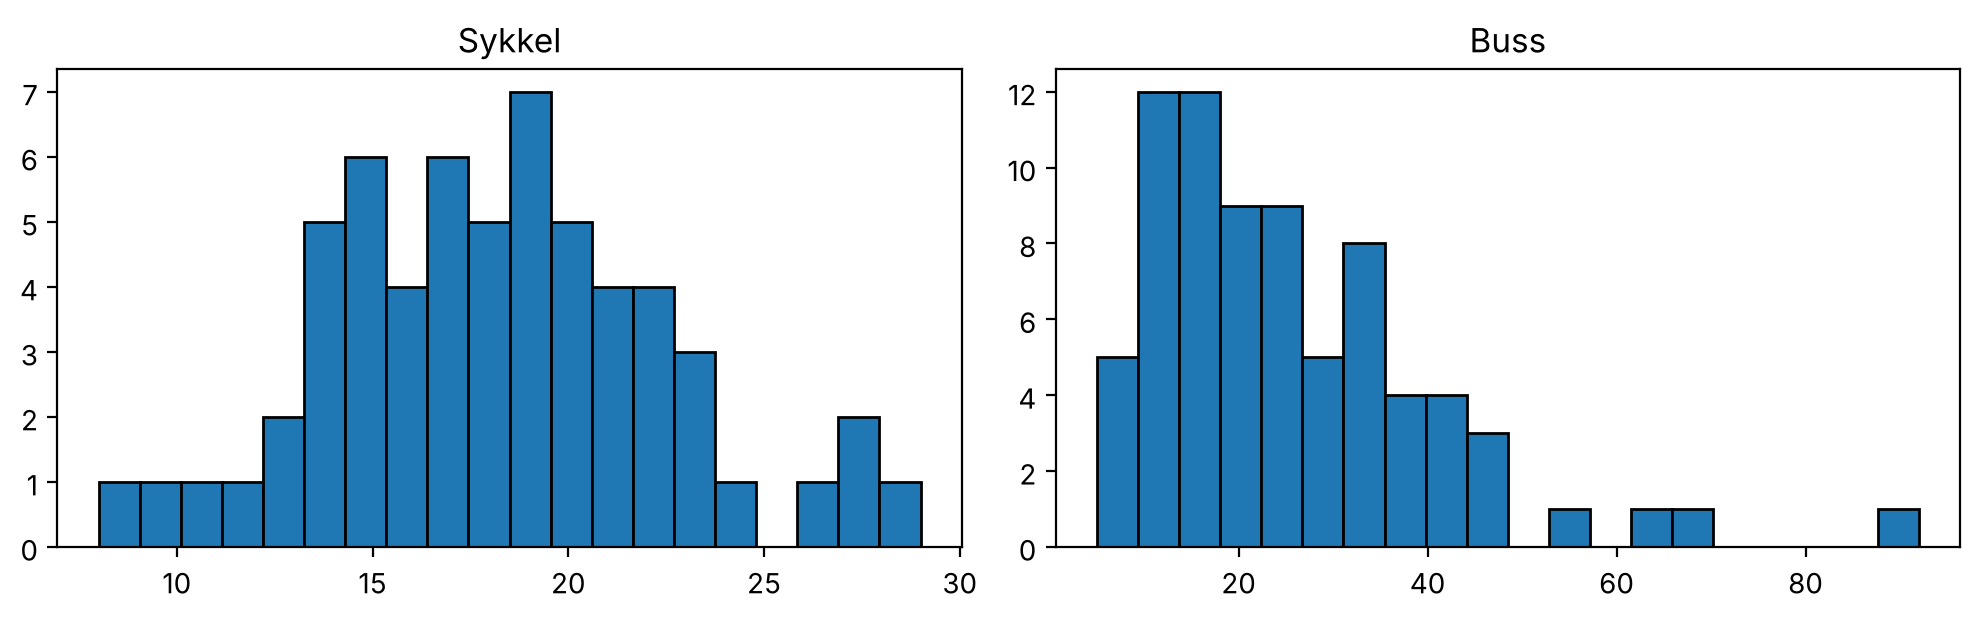

In [9]:
d4b = lag_data_4b()
t = beskriv(d4b, "reisetid", "transport"); display(t)
print("Kvartilbredde:"); print((t["Q3"] - t["Q1"]))
histogrammer(d4b, "reisetid", "transport")

,N,Mean,Median,Std,Min,Q1,Q3,Max,Skew,Kurt
kull,,,,,,,,,,
Kull 2025,90,77.067,78.0,16.149,0.0,71.0,89.0,99.0,-1.881,5.759
Kull 2026,95,60.042,60.0,11.829,21.0,53.5,66.5,91.0,-0.292,0.817


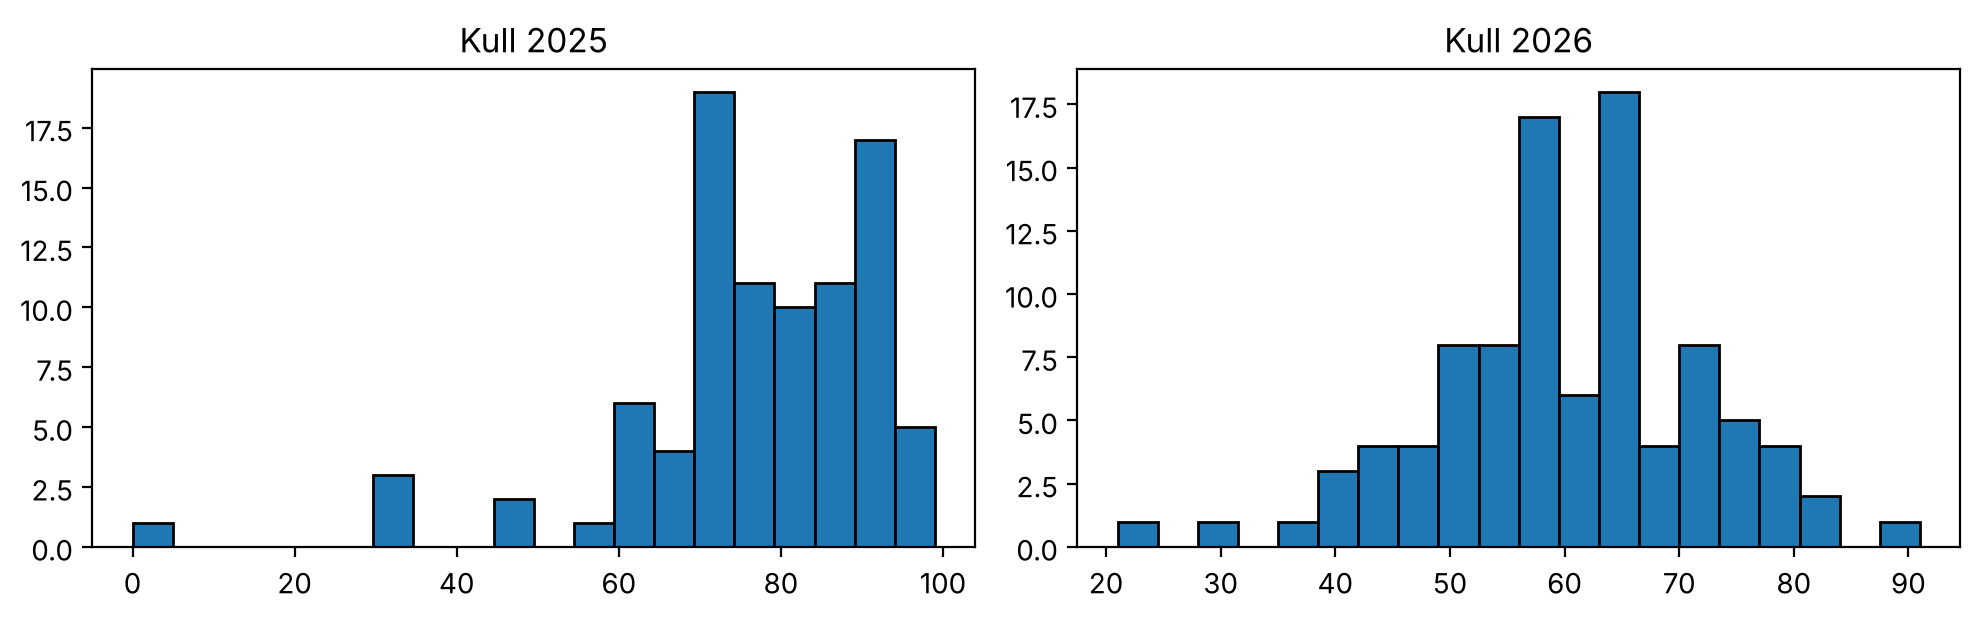

In [10]:
d4c = lag_data_4c()
display(beskriv(d4c, "poeng", "kull"))
histogrammer(d4c, "poeng", "kull")

## 5 Korrelasjonsmatrise

`DataFrame.corr()` gir Pearsons r. Matrisen er symmetrisk, og diagonalen er 1.

In [11]:
def korr(df, variabel):
    r = df.corr().round(2)
    display(r)
    rad = r[variabel].drop(variabel)
    print(f"Sterkest med {variabel}: {rad.abs().idxmax()} ({rad[rad.abs().idxmax()]})")
    print(f"Svakest med {variabel}: {rad.abs().idxmin()} ({rad[rad.abs().idxmin()]})")
    print(f"Mest negativ med {variabel}: {rad.idxmin()} ({rad.min()})")
    return r

r5a = korr(lag_data_5a(), "Karakter")
print("A =", r5a.loc["Karakter", "Studietimer"], " B =", r5a.loc["Sovn", "Skjermtid"], " C = 1.00")
print("Svakest med Sovn:", r5a["Sovn"].drop("Sovn").abs().idxmin())

,Studietimer,Karakter,Skjermtid,Sovn,Alder
Studietimer,1.00,0.56,-0.23,0.09,0.09
Karakter,0.56,1.00,-0.42,0.27,0.15
Skjermtid,-0.23,-0.42,1.00,-0.28,-0.23
Sovn,0.09,0.27,-0.28,1.00,0.02
Alder,0.09,0.15,-0.23,0.02,1.00


Sterkest med Karakter: Studietimer (0.56)
Svakest med Karakter: Alder (0.15)
Mest negativ med Karakter: Skjermtid (-0.42)
A = 0.56  B = -0.28  C = 1.00
Svakest med Sovn: Alder


In [12]:
r5b = korr(lag_data_5b(), "Pris")
print("A =", r5b.loc["Areal", "Pris"], " B =", r5b.loc["Byggaar", "Avstand"], " C = 1.00")
off = r5b.where(~np.eye(5, dtype=bool)).abs().stack()
print("Sterkeste par i hele matrisen:", off.idxmax(), off.max())
print("Svakest med Areal:", r5b["Areal"].drop("Areal").abs().idxmin())

,Pris,Areal,Rom,Avstand,Byggaar
Pris,1.00,0.84,0.70,-0.54,0.30
Areal,0.84,1.00,0.80,-0.29,0.17
Rom,0.70,0.80,1.00,-0.28,0.20
Avstand,-0.54,-0.29,-0.28,1.00,-0.24
Byggaar,0.30,0.17,0.20,-0.24,1.00


Sterkest med Pris: Areal (0.84)
Svakest med Pris: Byggaar (0.3)
Mest negativ med Pris: Avstand (-0.54)
A = 0.84  B = -0.24  C = 1.00
Sterkeste par i hele matrisen: ('Pris', 'Areal') 0.84
Svakest med Areal: Byggaar


In [13]:
r5c = korr(lag_data_5c(), "Trening")
print("A =", r5c.loc["Hvilepuls", "Trening"], " B =", r5c.loc["Hoyde", "Vekt"], " C = 1.00")
print("Sterkest positiv med Vekt:", r5c["Vekt"].drop("Vekt").idxmax())
print("Svakest med Hvilepuls:", r5c["Hvilepuls"].drop("Hvilepuls").abs().idxmin())

,Trening,Hvilepuls,Vekt,Hoyde,Sovn
Trening,1.00,-0.47,-0.11,0.10,0.15
Hvilepuls,-0.47,1.00,0.15,-0.06,-0.12
Vekt,-0.11,0.15,1.00,0.67,-0.11
Hoyde,0.10,-0.06,0.67,1.00,-0.01
Sovn,0.15,-0.12,-0.11,-0.01,1.00


Sterkest med Trening: Hvilepuls (-0.47)
Svakest med Trening: Hoyde (0.1)
Mest negativ med Trening: Hvilepuls (-0.47)
A = -0.47  B = 0.67  C = 1.00
Sterkest positiv med Vekt: Hoyde
Svakest med Hvilepuls: Hoyde


## 6 Total sannsynlighet og Bayes' setning

$P(B) = \sum_i P(A_i)P(B\mid A_i)$ og $P(A_i \mid B) = P(A_i)P(B\mid A_i)/P(B)$.

In [14]:
def bayes(prior, likelihood):
    prior, likelihood = np.array(prior), np.array(likelihood)
    total = (prior * likelihood).sum()
    return total, prior * likelihood / total

# 6.1  F = fisk, K = kjøtt
PU, post = bayes([0.4, 0.6], [0.10, 0.25])
print(f"6.1 b) P(U) = {PU:.3f}   c) P(K ∩ Uc) = {0.6 * 0.75:.3f}   d) P(F|U) = {post[0]:.4f}   e) P(V|U) = {0.3 * 0.5 / 0.25:.3f}")

# 6.2  S = spam
PF, post = bayes([0.2, 0.8], [0.9, 0.05])
print(f"6.2 a) P(F) = {PF:.3f}   b) P(S|F) = {post[0]:.4f}   c) {0.8 * 0.95:.3f}   d) P(S|Fc) = {0.2 * 0.1 / (1 - PF):.4f}")

# 6.3  selskap A, B, C
PD, post = bayes([0.5, 0.3, 0.2], [0.1, 0.2, 0.4])
print(f"6.3 a) P(D) = {PD:.3f}   P(A|D), P(B|D), P(C|D) = {post.round(4)}  sum = {post.sum():.1f}")

6.1 b) P(U) = 0.190   c) P(K ∩ Uc) = 0.450   d) P(F|U) = 0.2105   e) P(V|U) = 0.600
6.2 a) P(F) = 0.220   b) P(S|F) = 0.8182   c) 0.760   d) P(S|Fc) = 0.0256
6.3 a) P(D) = 0.190   P(A|D), P(B|D), P(C|D) = [0.2632 0.3158 0.4211]  sum = 1.0


## 7 Diskret sannsynlighetsfordeling

In [15]:
def diskret(x, p):
    x, p = np.array(x, float), np.array(p, float)
    E = (x * p).sum()
    Var = (x**2 * p).sum() - E**2
    print(f"E(X) = {E:.4f}, Var(X) = {Var:.4f}, SD(X) = {np.sqrt(Var):.4f}")
    return x, p

x, p = diskret([0, 1, 2, 3, 4], [0.20, 0.30, 1 - 0.75, 0.15, 0.10])
print("7.1  P(X>=2) =", p[x >= 2].sum().round(3), "  P(1<X<=3) =", p[(x > 1) & (x <= 3)].sum().round(3))

E(X) = 1.6500, Var(X) = 1.5275, SD(X) = 1.2359
7.1  P(X>=2) = 0.5   P(1<X<=3) = 0.4


In [16]:
x, p = diskret([0, 1, 2, 3, 4, 5], [0.15, 0.25, 0.30, 0.15, 0.10, 1 - 0.95])
print("7.2  P(X<=1) =", p[x <= 1].sum().round(3), "  P(2<=X<=4) =", p[(x >= 2) & (x <= 4)].sum().round(3))

E(X) = 1.9500, Var(X) = 1.8475, SD(X) = 1.3592
7.2  P(X<=1) = 0.4   P(2<=X<=4) = 0.55


In [17]:
x, p = diskret([-20, 0, 50, 200], [0.70, 0.20, 0.08, 1 - 0.98])
print("7.3  Tre lodd: E =", round(3 * (x * p).sum(), 2), "  P(X>0) =", p[x > 0].sum().round(3))

E(X) = -6.0000, Var(X) = 1244.0000, SD(X) = 35.2704
7.3  Tre lodd: E = -18.0   P(X>0) = 0.1


## 8 Binomisk fordeling

`stats.binom(n, p)` har `.pmf(k)` = P(X = k) og `.cdf(k)` = P(X ≤ k).

In [18]:
X = stats.binom(10, 0.30)
print(f"8.1  E = {X.mean():.2f}, SD = {X.std():.3f}, P(X=3) = {X.pmf(3):.3f}, "
      f"P(2<=X<=5) = {X.cdf(5) - X.cdf(1):.3f}, P(X>4) = {1 - X.cdf(4):.3f}")

X = stats.binom(8, 0.60)
print(f"8.2  E = {X.mean():.2f}, SD = {X.std():.3f}, P(X=8) = {X.pmf(8):.3f}, P(X<=3) = {X.cdf(3):.3f}, "
      f"P(X>=6) = {1 - X.cdf(5):.3f}, P(X=4) = {X.pmf(4):.3f}")

X = stats.binom(12, 0.15)
print(f"8.3  E = {X.mean():.2f}, SD = {X.std():.3f}, P(X=0) = {X.pmf(0):.3f}, P(X<=2) = {X.cdf(2):.3f}, "
      f"P(1<=X<=3) = {X.cdf(3) - X.cdf(0):.3f}")

8.1  E = 3.00, SD = 1.449, P(X=3) = 0.267, P(2<=X<=5) = 0.803, P(X>4) = 0.150
8.2  E = 4.80, SD = 1.386, P(X=8) = 0.017, P(X<=3) = 0.174, P(X>=6) = 0.315, P(X=4) = 0.232
8.3  E = 1.80, SD = 1.237, P(X=0) = 0.142, P(X<=2) = 0.736, P(1<=X<=3) = 0.766


## 9 Normalfordelingskurver

Vi tegner kurvene og regner ut sannsynlighetene som påstandene handler om.

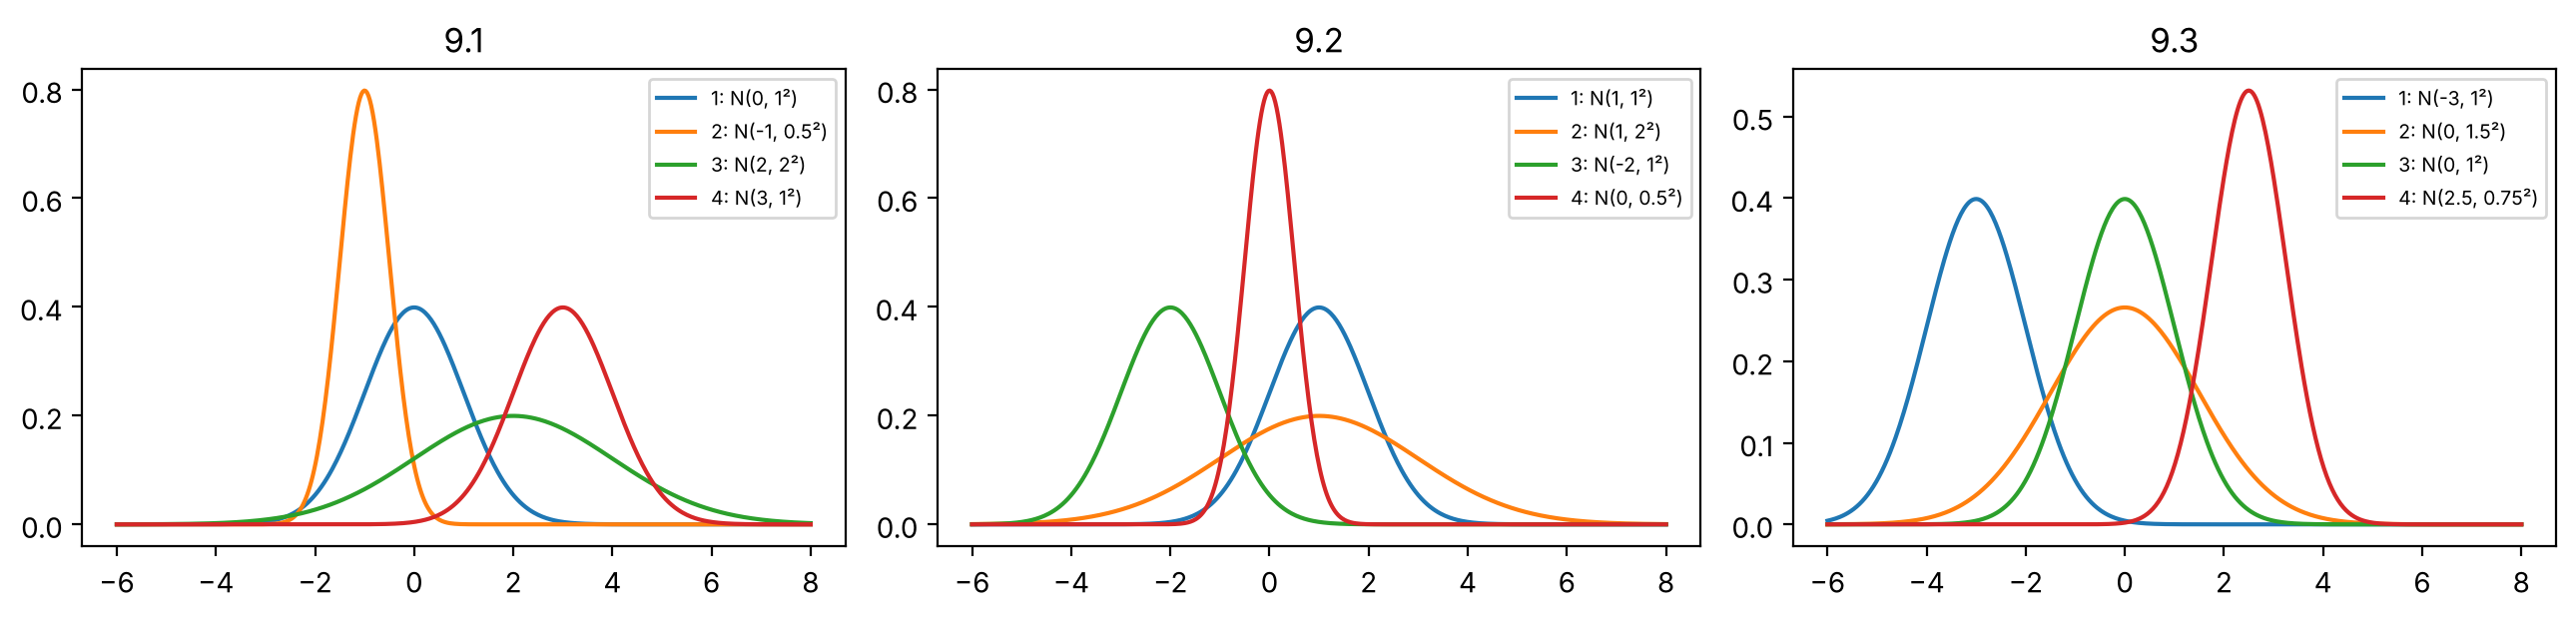

,oppgave,kurve,mu,sigma,P(X<0),P(X>2),P(X<-2),P(-1<X<1),P(0.5<X<1.5)
0,9.1,1,0.0,1.00,0.500,0.023,0.023,0.683,0.242
1,9.1,2,-1.0,0.50,0.977,0.000,0.023,0.500,0.001
2,9.1,3,2.0,2.00,0.159,0.500,0.023,0.242,0.175
3,9.1,4,3.0,1.00,0.001,0.841,0.000,0.023,0.061
4,9.2,1,1.0,1.00,0.159,0.159,0.001,0.477,0.383
5,9.2,2,1.0,2.00,0.309,0.309,0.067,0.341,0.197
6,9.2,3,-2.0,1.00,0.977,0.000,0.500,0.157,0.006
7,9.2,4,0.0,0.50,0.500,0.000,0.000,0.954,0.157
8,9.3,1,-3.0,1.00,0.999,0.000,0.841,0.023,0.000
9,9.3,2,0.0,1.50,0.500,0.091,0.091,0.495,0.211


In [19]:
kurver = {"9.1": [(0, 1), (-1, 0.5), (2, 2), (3, 1)],
          "9.2": [(1, 1), (1, 2), (-2, 1), (0, 0.5)],
          "9.3": [(-3, 1), (0, 1.5), (0, 1), (2.5, 0.75)]}
xs = np.linspace(-6, 8, 500)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
rader = []
for ax, (navn, par) in zip(axes, kurver.items()):
    for i, (m, s) in enumerate(par, start=1):
        ax.plot(xs, stats.norm.pdf(xs, m, s), label=f"{i}: N({m}, {s}²)")
        N = stats.norm(m, s)
        rader.append({"oppgave": navn, "kurve": i, "mu": m, "sigma": s, "P(X<0)": N.cdf(0), "P(X>2)": N.sf(2),
                      "P(X<-2)": N.cdf(-2), "P(-1<X<1)": N.cdf(1) - N.cdf(-1), "P(0.5<X<1.5)": N.cdf(1.5) - N.cdf(0.5)})
    ax.set_title(navn); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
pd.DataFrame(rader).round(3)

## 10 Normalfordelingen og standardisering

Sum av $n$ uavhengige: $N(n\mu,\ n\sigma^2)$. Gjennomsnitt: $N(\mu,\ \sigma^2/n)$.

In [20]:
X = stats.norm(6, 1.5)
print("10.1  a)", round(X.cdf(7.5), 4), " b)", round(X.sf(9), 4), " c)", round(X.cdf(7.5) - X.cdf(4.5), 4),
      " d)", round(stats.norm(4 * 6, 1.5 * np.sqrt(4)).sf(27), 4),
      " e)", round(stats.norm(6, 1.5 / np.sqrt(25)).cdf(5.4), 4))

X = stats.norm(750, 20)
print("10.2  a)", round(X.cdf(720), 4), " b)", round(X.sf(790), 4), " c)", round(X.cdf(760) - X.cdf(740), 4),
      " d)", round(stats.norm(3000, 40).cdf(2980), 4), " e)", round(stats.norm(750, 5).sf(757.5), 4),
      " f)", round(X.ppf(0.95), 1))

X = stats.norm(5, 2)
print("10.3  a)", round(X.cdf(6), 4), " b)", round(X.sf(8), 4), " c)", round(X.cdf(7) - X.cdf(3), 4),
      " d)", round(stats.norm(20, 4).sf(24), 4), " e)", round(stats.norm(5, 0.5).cdf(4), 4),
      " f)", round(X.ppf(0.8413), 2))

10.1  a) 0.8413  b) 0.0228  c) 0.6827  d) 0.1587  e) 0.0228
10.2  a) 0.0668  b) 0.0228  c) 0.3829  d) 0.3085  e) 0.0668  f) 782.9
10.3  a) 0.6915  b) 0.0668  c) 0.6827  d) 0.1587  e) 0.0228  f) 7.0


## 11 Sentralgrenseteoremet

En liten simulering viser at $\bar X$ blir normalfordelt selv om populasjonen er skjev.

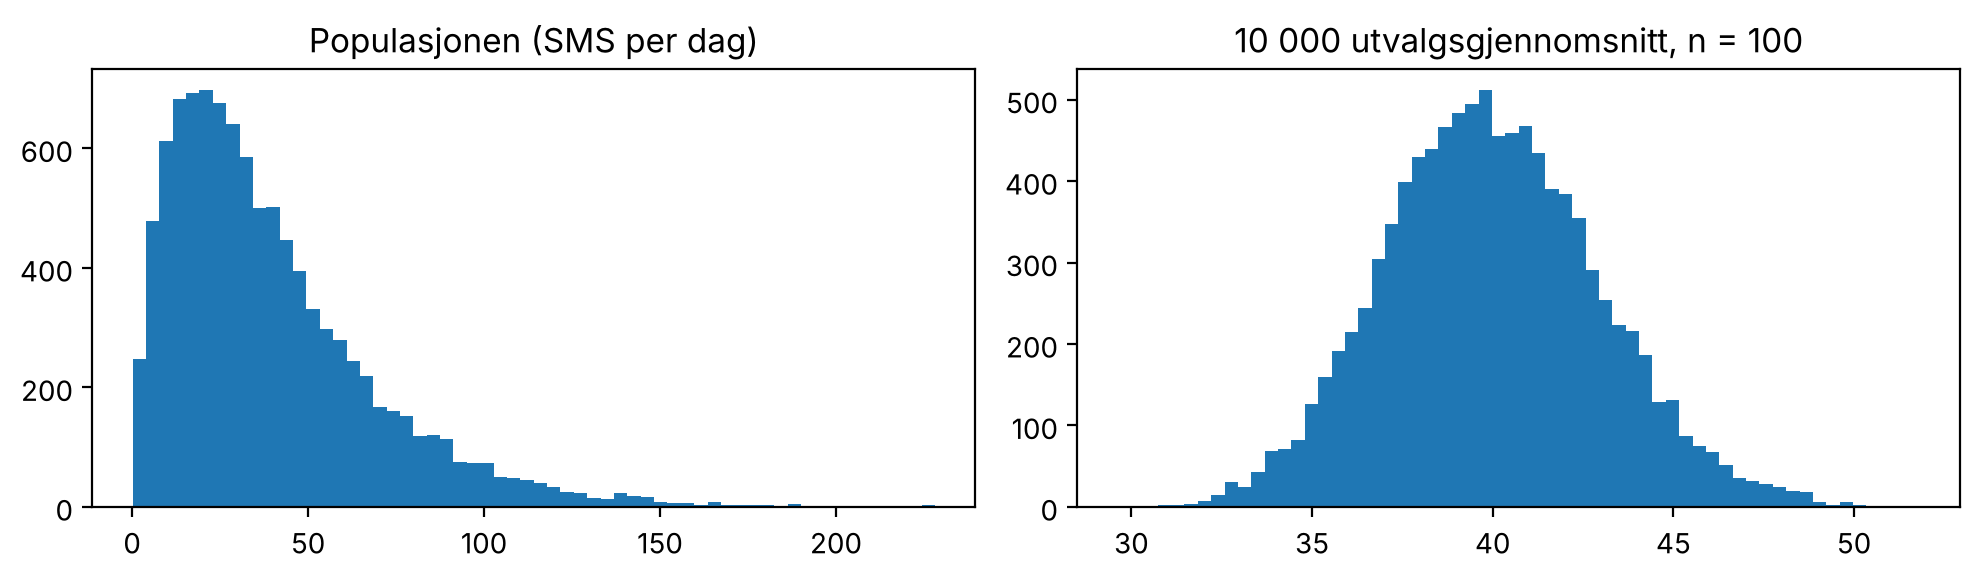

SD for simulerte gjennomsnitt: 2.99  (teori: 30/sqrt(100) = 3)


In [21]:
rng = np.random.default_rng(1)
# høyreskjev populasjon med mu = 40 og sigma = 30 (gammafordeling)
form = (40 / 30) ** 2
pop = lambda size: rng.gamma(form, 40 / form, size)
snitt = pop((10_000, 100)).mean(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(pop(10_000), bins=60); axes[0].set_title("Populasjonen (SMS per dag)")
axes[1].hist(snitt, bins=60); axes[1].set_title("10 000 utvalgsgjennomsnitt, n = 100")
plt.tight_layout(); plt.show()
print("SD for simulerte gjennomsnitt:", snitt.std().round(2), " (teori: 30/sqrt(100) = 3)")

In [22]:
def sgt(mu, sigma, n):
    se = sigma / np.sqrt(n)
    return se, stats.norm(mu, se)

se, Xbar = sgt(40, 30, 100)
print(f"11.1  SE = {se}, P(Xbar>46) = {Xbar.sf(46):.4f}, P(37<Xbar<43) = {Xbar.cdf(43) - Xbar.cdf(37):.4f}, "
      f"n for SE<=2: {np.ceil((30 / 2) ** 2):.0f}")
se, Xbar = sgt(50, 50, 64)
print(f"11.2  SE = {se}, P(Xbar>62.5) = {Xbar.sf(62.5):.4f}, P(Xbar<40) = {Xbar.cdf(40):.4f}, "
      f"n for SE<=5: {np.ceil((50 / 5) ** 2):.0f}")
se, Xbar = sgt(200, 90, 81)
print(f"11.3  SE(n=9) = {90 / 3}, SE(n=81) = {se}, P(Xbar>215) = {Xbar.sf(215):.4f}, "
      f"n for SE<=6: {np.ceil((90 / 6) ** 2):.0f}")

11.1  SE = 3.0, P(Xbar>46) = 0.0228, P(37<Xbar<43) = 0.6827, n for SE<=2: 225
11.2  SE = 6.25, P(Xbar>62.5) = 0.0228, P(Xbar<40) = 0.0548, n for SE<=5: 100
11.3  SE(n=9) = 30.0, SE(n=81) = 10.0, P(Xbar>215) = 0.0668, n for SE<=6: 225


## 12–14 Begrepsoppgaver

Oppgavene om deskriptiv statistikk og inferens, valg av analyse og p-verdier løses uten regning (se løsningsforslaget).
To av påstandene kan likevel sjekkes med simulering.

**14.3 b)** Når alle nullhypoteser er sanne, gir 20 tester i snitt $20 \cdot 0.05 = 1$ falskt signifikant resultat.

In [23]:
rng = np.random.default_rng(2)
antall = []
for _ in range(2000):
    p = [stats.ttest_1samp(rng.normal(0, 1, 30), 0).pvalue for _ in range(20)]
    antall.append(np.sum(np.array(p) < 0.05))
print("Gjennomsnittlig antall signifikante av 20 tester (H0 sann):", np.mean(antall).round(2))

Gjennomsnittlig antall signifikante av 20 tester (H0 sann): 0.99


**14.2 b)** Med samme effekt og spredning gir større $n$ lavere p-verdi:

In [24]:
for n in [20, 80, 320]:
    t = 0.3 / (1 / np.sqrt(n))   # effekt 0.3, SD 1
    print(f"n = {n:4d}: t = {t:.2f}, tosidig p = {2 * stats.t.sf(t, n - 1):.4f}")

n =   20: t = 1.34, tosidig p = 0.1955
n =   80: t = 2.68, tosidig p = 0.0089
n =  320: t = 5.37, tosidig p = 0.0000


## 15 Konfidensintervall (t)

In [25]:
def ki(n, xbar, s, niva=0.95):
    se = s / np.sqrt(n)
    t = stats.t.ppf(1 - (1 - niva) / 2, n - 1)
    return f"[{xbar - t * se:.2f}, {xbar + t * se:.2f}]  (t = {t:.3f}, SE = {se:.3f})"

print("15.1  95 %:", ki(10, 245, 32), "  90 %:", ki(10, 245, 32, 0.90))
print("15.2  95 %:", ki(16, 18.4, 2.4), "  90 %:", ki(16, 18.4, 2.4, 0.90))
print("      n = 64:", ki(64, 18.4, 2.4), "  S = 3:", ki(16, 18.4, 3.0), "  99 %:", ki(16, 18.4, 2.4, 0.99))
print("15.3  95 %:", ki(25, 6.8, 1.0), "  99 %:", ki(25, 6.8, 1.0, 0.99))

15.1  95 %: [222.11, 267.89]  (t = 2.262, SE = 10.119)   90 %: [226.45, 263.55]  (t = 1.833, SE = 10.119)
15.2  95 %: [17.12, 19.68]  (t = 2.131, SE = 0.600)   90 %: [17.35, 19.45]  (t = 1.753, SE = 0.600)
      n = 64: [17.80, 19.00]  (t = 1.998, SE = 0.300)   S = 3: [16.80, 20.00]  (t = 2.131, SE = 0.750)   99 %: [16.63, 20.17]  (t = 2.947, SE = 0.600)
15.3  95 %: [6.39, 7.21]  (t = 2.064, SE = 0.200)   99 %: [6.24, 7.36]  (t = 2.797, SE = 0.200)


## 16 t-test for ett gjennomsnitt (fra oppsummerte tall)

In [26]:
def ttest_ett(n, xbar, s, mu0, alternativ):
    t = (xbar - mu0) / (s / np.sqrt(n))
    df = n - 1
    p = {"greater": stats.t.sf(t, df), "less": stats.t.cdf(t, df), "two-sided": 2 * stats.t.sf(abs(t), df)}[alternativ]
    print(f"t = {t:.3f}, df = {df}, p = {p:.4f} -> {'forkast H0' if p < 0.05 else 'behold H0'}")

print("16.1", end="  "); ttest_ett(12, 52.3, 6.1, 48, "greater")
print("16.2", end="  "); ttest_ett(20, 32.1, 4.5, 30, "two-sided")
print("  ensidig", end="  "); ttest_ett(20, 32.1, 4.5, 30, "greater")
print("16.3", end="  "); ttest_ett(9, 497.2, 3.6, 500, "less")

16.1  t = 2.442, df = 11, p = 0.0164 -> forkast H0
16.2  t = 2.087, df = 19, p = 0.0506 -> behold H0
  ensidig  t = 2.087, df = 19, p = 0.0253 -> forkast H0
16.3  t = -2.333, df = 8, p = 0.0240 -> forkast H0


## 17 Andelstest

Vi bruker $p_0$ i standardfeilen, slik som i læreboka. (`statsmodels` sin `proportions_ztest` bruker $\hat p$
som standard. Bruk `prop_var=p0` for å få læreboksformelen.)

In [27]:
from statsmodels.stats.proportion import proportions_ztest

def andelstest(x, n, p0, alternativ):
    phat = x / n
    z = (phat - p0) / np.sqrt(p0 * (1 - p0) / n)
    p = {"larger": stats.norm.sf(z), "smaller": stats.norm.cdf(z), "two-sided": 2 * stats.norm.sf(abs(z))}[alternativ]
    z_sm, p_sm = proportions_ztest(x, n, p0, alternative=alternativ, prop_var=p0)
    print(f"phat = {phat:.3f}, z = {z:.3f}, p = {p:.4f}   (statsmodels: z = {z_sm:.3f}, p = {p_sm:.4f})")

print("17.1", end="  "); andelstest(145, 250, 0.50, "larger")
print("17.2", end="  "); andelstest(21, 120, 0.25, "smaller")
print("17.3", end="  "); andelstest(92, 400, 0.20, "two-sided")
print("17.2 d) n*p0 =", 120 * 0.25, " n*(1-p0) =", 120 * 0.75)

17.1  phat = 0.580, z = 2.530, p = 0.0057   (statsmodels: z = 2.530, p = 0.0057)
17.2  phat = 0.175, z = -1.897, p = 0.0289   (statsmodels: z = -1.897, p = 0.0289)
17.3  phat = 0.230, z = 1.500, p = 0.1336   (statsmodels: z = 1.500, p = 0.1336)
17.2 d) n*p0 = 30.0  n*(1-p0) = 90.0


## 18 Uavhengig t-test fra oppsummerte tall

`stats.ttest_ind_from_stats` gir t og p. Konfidensintervall og Cohens d regner vi ut selv med felles standardavvik.

In [28]:
def ttest_to(n1, m1, s1, n2, m2, s2):
    res = stats.ttest_ind_from_stats(m1, s1, n1, m2, s2, n2, equal_var=True)
    df = n1 + n2 - 2
    sp = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / df)
    se = sp * np.sqrt(1 / n1 + 1 / n2)
    tk = stats.t.ppf(0.975, df)
    print(f"diff = {m1 - m2:.2f}, t = {res.statistic:.3f}, df = {df}, p = {res.pvalue:.4f}, "
          f"95 % KI = [{m1 - m2 - tk * se:.2f}, {m1 - m2 + tk * se:.2f}], Cohens d = {(m1 - m2) / sp:.3f}")

print("18.1", end="  "); ttest_to(45, 22.4, 6.1, 38, 26.1, 7.0); print("     andel bachelor =", round(45 / 83, 3))
print("18.2", end="  "); ttest_to(60, 182, 21, 55, 188, 24); print("     t_0.025(113) =", round(stats.t.ppf(0.975, 113), 3))
print("18.3", end="  "); ttest_to(30, 285, 28, 30, 302, 31)

18.1  diff = -3.70, t = -2.573, df = 81, p = 0.0119, 95 % KI = [-6.56, -0.84], Cohens d = -0.567
     andel bachelor = 0.542
18.2  diff = -6.00, t = -1.430, df = 113, p = 0.1556, 95 % KI = [-14.32, 2.32], Cohens d = -0.267
     t_0.025(113) = 1.981
18.3  diff = -17.00, t = -2.229, df = 58, p = 0.0297, 95 % KI = [-32.27, -1.73], Cohens d = -0.576


## 19 Paret t-test fra oppsummerte tall

Testen bygger på differansene: $t = \bar d/(s_d/\sqrt n)$. Cohens $d$ i utskriftene er $d_{av} = \bar d / \sqrt{(s_1^2+s_2^2)/2}$.

In [29]:
def paret(n, m_for, s_for, m_etter, s_etter, s_d, alternativ="two-sided"):
    dbar = m_etter - m_for
    se = s_d / np.sqrt(n)
    t = dbar / se
    df = n - 1
    p = 2 * stats.t.sf(abs(t), df) if alternativ == "two-sided" else stats.t.sf(t, df)
    tk = stats.t.ppf(0.975, df)
    d_av = dbar / np.sqrt((s_for**2 + s_etter**2) / 2)
    print(f"dbar = {dbar:.2f}, SE = {se:.3f}, t = {t:.3f}, df = {df}, p = {p:.4f}, "
          f"95 % KI = [{dbar - tk * se:.2f}, {dbar + tk * se:.2f}], d_av = {d_av:.3f}, d_z = {dbar / s_d:.3f}")

print("19.1", end="  "); paret(24, 62.4, 10.2, 66.1, 9.8, 7.4)
print("19.2", end="  "); paret(15, 72.3, 8.1, 69.8, 7.6, 5.2)
print("19.3", end="  "); paret(40, 118.5, 14.2, 121.7, 15.0, 8.0, "greater")

19.1  dbar = 3.70, SE = 1.511, t = 2.449, df = 23, p = 0.0223, 95 % KI = [0.58, 6.82], d_av = 0.370, d_z = 0.500
19.2  dbar = -2.50, SE = 1.343, t = -1.862, df = 14, p = 0.0837, 95 % KI = [-5.38, 0.38], d_av = -0.318, d_z = -0.481
19.3  dbar = 3.20, SE = 1.265, t = 2.530, df = 39, p = 0.0078, 95 % KI = [0.64, 5.76], d_av = 0.219, d_z = 0.400


Med rådata ville du brukt `stats.ttest_rel(etter, for_)`. Eksempel med simulerte data:

In [30]:
rng = np.random.default_rng(3)
for_ = rng.normal(62, 10, 24)
etter = for_ + rng.normal(3.7, 7.4, 24)
print(stats.ttest_rel(etter, for_))

TtestResult(statistic=np.float64(2.5496505345733094), pvalue=np.float64(0.017912704623531638), df=np.int64(23))


## 20 Enveis ANOVA og Levenes test

In [31]:
def anova(d, y, g):
    grupper = [x[y].values for _, x in d.groupby(g, sort=False)]
    display(d.groupby(g, sort=False)[y].agg(["count", "mean", "std"]))
    k, n = len(grupper), len(d)
    ssb = sum(len(v) * (v.mean() - d[y].mean())**2 for v in grupper)
    ssw = sum(((v - v.mean())**2).sum() for v in grupper)
    msb, msw = ssb / (k - 1), ssw / (n - k)
    F = msb / msw
    print(f"SSB = {ssb:.2f}, SSW = {ssw:.2f}, df = ({k - 1}, {n - k}), MSB = {msb:.2f}, MSW = {msw:.2f}, F = {F:.3f}")
    print("scipy f_oneway:", stats.f_oneway(*grupper))
    print("Levene:        ", stats.levene(*grupper))
    print(f"Kritisk F_0.05({k - 1}, {n - k}) = {stats.f.ppf(0.95, k - 1, n - k):.3f}")

anova(lag_data_20a(), "studietid", "fakultet")

,count,mean,std
fakultet,,,
Okonomi,42,23.374,7.778
Ingenior,38,26.158,7.423
Helse,45,31.258,7.372
Samfunn,40,24.108,6.308


SSB = 1658.45, SSW = 8461.57, df = (3, 161), MSB = 552.82, MSW = 52.56, F = 10.519
scipy f_oneway: F_onewayResult(statistic=np.float64(10.51857248487616), pvalue=np.float64(2.3460125703068213e-06))
Levene:         LeveneResult(statistic=np.float64(1.1223408812890554), pvalue=np.float64(0.34175704085901804))
Kritisk F_0.05(3, 161) = 2.661


In [32]:
anova(lag_data_20b(), "ventetid", "kantine")

,count,mean,std
kantine,,,
Kantine A,35,6.511,1.858
Kantine B,40,6.410,1.784
Kantine C,30,5.633,1.955


SSB = 14.74, SSW = 352.20, df = (2, 102), MSB = 7.37, MSW = 3.45, F = 2.135
scipy f_oneway: F_onewayResult(statistic=np.float64(2.134644464154372), pvalue=np.float64(0.12354132471609312))
Levene:         LeveneResult(statistic=np.float64(0.06810031721312383), pvalue=np.float64(0.9342091929981762))
Kritisk F_0.05(2, 102) = 3.085


In [33]:
d20c = lag_data_20c()
anova(d20c, "pris", "bydel")
# Ved ulik varians er Welch-ANOVA et tryggere valg. Den kan regnes med statsmodels:
from statsmodels.stats.oneway import anova_oneway
print(anova_oneway(d20c["pris"], d20c["bydel"], use_var="unequal"))

,count,mean,std
bydel,,,
Sentrum,18,53.556,7.509
Nord,14,44.000,2.935
Sor,16,46.062,4.509
Ost,15,43.133,4.340
Vest,20,48.750,6.463


SSB = 1181.74, SSW = 2432.87, df = (4, 78), MSB = 295.43, MSW = 31.19, F = 9.472
scipy f_oneway: F_onewayResult(statistic=np.float64(9.471907171256857), pvalue=np.float64(2.7074467400520733e-06))
Levene:         LeveneResult(statistic=np.float64(2.8313522118190626), pvalue=np.float64(0.03004670787132803))
Kritisk F_0.05(4, 78) = 2.489
AnovaResult(statistic=np.float64(8.111898853997028), pvalue=np.float64(7.50178103263403e-05), df=(4.0, np.float64(38.702261757020864)), df_num=4.0, df_denom=np.float64(38.702261757020864), nobs_total=np.float64(83.0), n_groups=5, means=array([44.        , 43.13333333, 53.55555556, 46.0625    , 48.75      ]), nobs=array([14., 15., 18., 16., 20.]), vars_=array([ 8.61538462, 18.83809524, 56.37908497, 20.32916667, 41.77631579]), use_var='unequal', welch_correction=True, df2=None, df_num2=None, pvalue2=None)


Hvis du vil finne *hvilke* grupper som er forskjellige (oppgave 20.1 e), kan du bruke Tukeys test:

In [34]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
d20a = lag_data_20a()
print(pairwise_tukeyhsd(d20a["studietid"], d20a["fakultet"]))

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1   group2  meandiff p-adj   lower    upper  reject
---------------------------------------------------------
   Helse Ingenior  -5.0999 0.0091  -9.2463 -0.9535   True
   Helse  Okonomi   -7.884    0.0 -11.9219 -3.8461   True
   Helse  Samfunn  -7.1503 0.0001 -11.2401 -3.0605   True
Ingenior  Okonomi  -2.7841 0.3191  -6.9977  1.4295  False
Ingenior  Samfunn  -2.0504  0.597  -6.3138   2.213  False
 Okonomi  Samfunn   0.7337  0.968  -3.4243  4.8917  False
---------------------------------------------------------


## 21 Enkel lineær regresjon

Den standardiserte koeffisienten er $b \cdot s_x / s_y$. I enkel regresjon er den lik korrelasjonen $r$.

In [35]:
def regresjon(d, formel):
    m = smf.ols(formel, d).fit()
    y = formel.split("~")[0].strip()
    std = {x: m.params[x] * d[x].std() / d[y].std() for x in m.params.index[1:]}
    tab = pd.DataFrame({"coef": m.params, "se": m.bse, "t": m.tvalues, "p": m.pvalues,
                        "std.coef": pd.Series(std)})
    print(f"N = {int(m.nobs)}, R² = {m.rsquared:.3f}, justert R² = {m.rsquared_adj:.3f}")
    display(tab.round(3))
    return m

m21a = regresjon(lag_data_21a(), "leie ~ areal")
print("Predikert leie, 25 m²:", m21a.predict(pd.DataFrame({"areal": [25]})).round(0).values)
print("r =", np.sqrt(m21a.rsquared).round(3))

N = 90, R² = 0.713, justert R² = 0.710


,coef,se,t,p,std.coef
Intercept,2388.521,275.875,8.658,0.0,NaN
areal,152.737,10.327,14.790,0.0,0.844


Predikert leie, 25 m²: [6207.]
r = 0.844


N = 120, R² = 0.438, justert R² = 0.433


,coef,se,t,p,std.coef
Intercept,30.913,2.367,13.063,0.0,NaN
studietimer,1.092,0.114,9.588,0.0,0.662


Predikert poeng, 20 timer: [52.75]
Dataområde for studietimer: 5.0 – 34.0


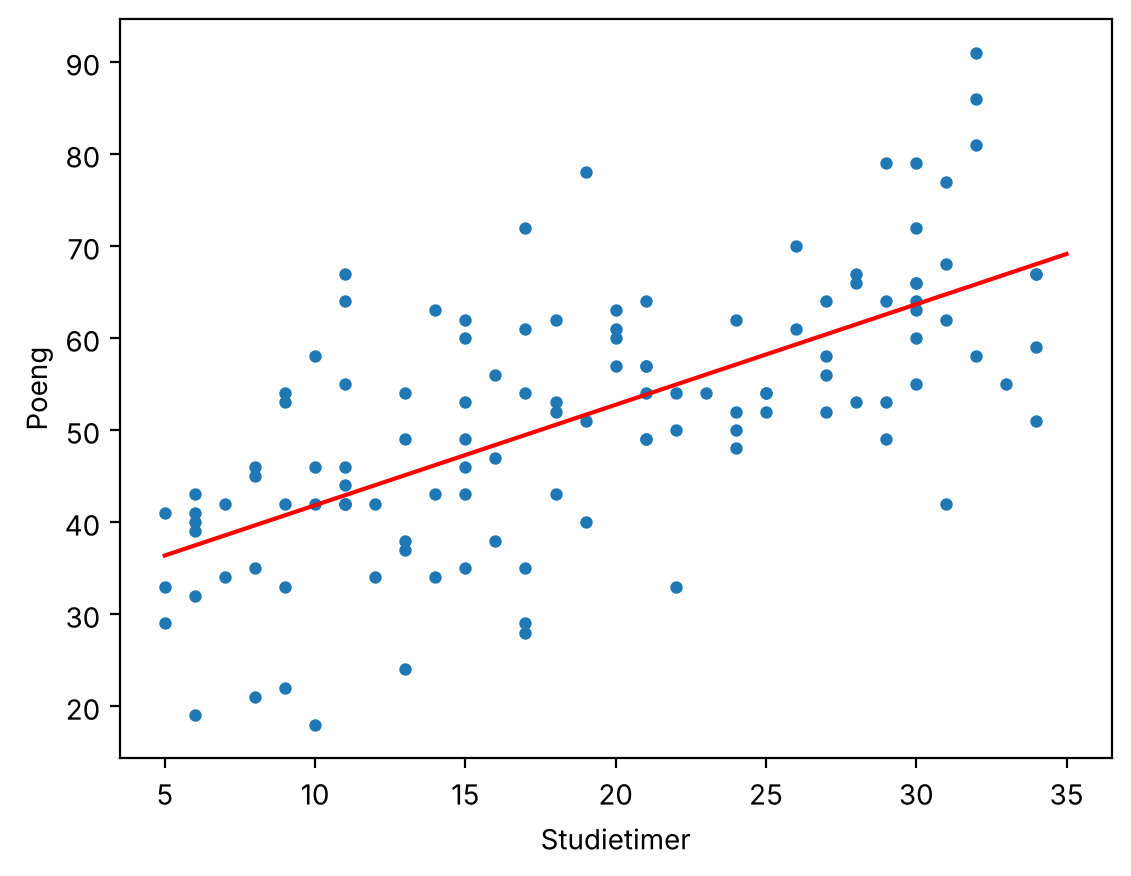

In [36]:
d21b = lag_data_21b()
m21b = regresjon(d21b, "poeng ~ studietimer")
print("Predikert poeng, 20 timer:", m21b.predict(pd.DataFrame({"studietimer": [20]})).round(2).values)
print("Dataområde for studietimer:", d21b.studietimer.min(), "–", d21b.studietimer.max())
plt.scatter(d21b.studietimer, d21b.poeng, s=12)
xs = np.linspace(5, 35, 10); plt.plot(xs, m21b.params.iloc[0] + m21b.params.iloc[1] * xs, color="red")
plt.xlabel("Studietimer"); plt.ylabel("Poeng"); plt.show()

In [37]:
m21c = regresjon(lag_data_21c(), "kwh ~ temperatur")
print("Predikert kWh ved -10 °C:", m21c.predict(pd.DataFrame({"temperatur": [-10]})).round(2).values)
print("r =", (-np.sqrt(m21c.rsquared)).round(3))

N = 100, R² = 0.784, justert R² = 0.781


,coef,se,t,p,std.coef
Intercept,59.768,0.866,68.980,0.0,NaN
temperatur,-1.736,0.092,-18.837,0.0,-0.885


Predikert kWh ved -10 °C: [77.13]
r = -0.885


## 22 Multippel lineær regresjon

Prediksjonene i løsningsforslaget bruker koeffisientene rundet til tre desimaler, slik de står i utskriften.
`predict()` bruker de urundede koeffisientene, så svarene kan avvike litt.

In [38]:
m22a = regresjon(lag_data_22a(), "leie ~ areal + avstand + alder")
print("Økning i leie for +5 m²:", (5 * m22a.params["areal"]).round(1))
print("Prediksjon:", m22a.predict(pd.DataFrame({"areal": [20], "avstand": [3], "alder": [30]})).round(0).values)

N = 150, R² = 0.810, justert R² = 0.807


,coef,se,t,p,std.coef
Intercept,2581.643,243.024,10.623,0.000,NaN
alder,1.813,2.927,0.619,0.537,0.023
areal,157.289,6.534,24.072,0.000,0.883
avstand,-91.655,18.900,-4.850,0.000,-0.175


Økning i leie for +5 m²: 786.4
Prediksjon: [5507.]


In [39]:
m22b = regresjon(lag_data_22b(), "poeng ~ studietimer + oppmote + kaffe")
print("Økning for +10 prosentpoeng oppmøte:", (10 * m22b.params["oppmote"]).round(2))
print("Prediksjon:", m22b.predict(pd.DataFrame({"studietimer": [20], "oppmote": [80], "kaffe": [2]})).round(2).values)

N = 160, R² = 0.568, justert R² = 0.559


,coef,se,t,p,std.coef
Intercept,14.488,2.973,4.874,0.000,NaN
kaffe,0.143,0.390,0.367,0.714,0.019
oppmote,0.277,0.033,8.303,0.000,0.438
studietimer,0.930,0.079,11.817,0.000,0.623


Økning for +10 prosentpoeng oppmøte: 2.77
Prediksjon: [55.52]


In [40]:
d22c = lag_data_22c()
m22c = regresjon(d22c, "pris ~ areal + soverom + avstand")
print("Endring for +2 km:", (2 * m22c.params["avstand"]).round(3), "mill. kr")
print("Prediksjon:", m22c.predict(pd.DataFrame({"areal": [80], "soverom": [3], "avstand": [5]})).round(3).values)
print("\nKorrelasjon mellom areal og soverom:", d22c[["areal", "soverom"]].corr().iloc[0, 1].round(2))
print("Soverom alene:")
_ = regresjon(d22c, "pris ~ soverom")

N = 200, R² = 0.863, justert R² = 0.861


,coef,se,t,p,std.coef
Intercept,1.212,0.137,8.841,0.000,NaN
areal,0.041,0.002,17.825,0.000,0.851
avstand,-0.124,0.009,-13.156,0.000,-0.348
soverom,0.017,0.060,0.287,0.775,0.014


Endring for +2 km: -0.249 mill. kr
Prediksjon: [3.924]

Korrelasjon mellom areal og soverom: 0.83
Soverom alene:
N = 200, R² = 0.526, justert R² = 0.524


,coef,se,t,p,std.coef
Intercept,1.164,0.189,6.152,0.0,NaN
soverom,0.918,0.062,14.838,0.0,0.726
